# Simulation

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML
import matplotlib 
matplotlib.rc('font', family='serif')
matplotlib.rc('font', serif='STIXGeneral')
from cmcrameri import cm  #cmap=cm.lipari 
matplotlib.rcParams['animation.embed_limit'] = 50  # MB

### Global variables

In [14]:
dimension = 256*2 #size of matrix
background_num = 5 #No. of background objects # updated from original
frames_num = 50    # number of animation frames 


## Object & background 

In [15]:
# Fixed background
random_num = np.random.default_rng(2)
bg_positions = random_num.integers(0.2*dimension,0.8*dimension, size=(background_num, 2))

In [16]:

# Object matrix
def make_object(t):
    '''creates a vertical and horizontal linear moving object relative to a fixed background'''

    Obj = np.zeros((dimension, dimension))

    # Static background dots
    for y, x in bg_positions:
        Obj[y, x] = 1

    centre_x = dimension // 2
    centre_y = dimension // 2
    amp_x = 60
    amp_y = 60

    # Object 1 (horizontal linear)
    x1 = int(centre_x + amp_x * np.sin(t))
    y1 = int(centre_y+20) # updates from original

    # Object 2 (vertical linear)
    x2 = int(centre_x-10) #updated from original
    y2 = int(centre_y + amp_y * np.sin(t))

    Obj[y1, x1] = 1
    Obj[y2, x2] = 1

    Obj = gaussian_filter(Obj, sigma=2)

    return Obj

### Animation

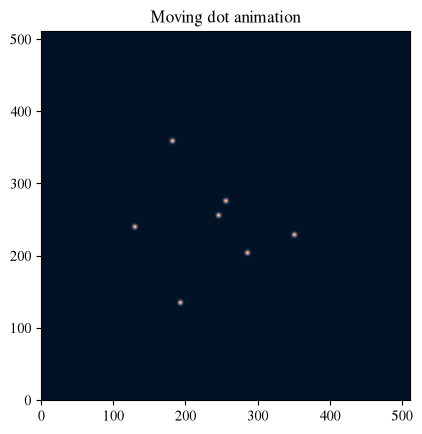

In [17]:
# animation
fig, ax = plt.subplots()
img = ax.imshow(make_object(0), origin='lower',cmap=cm.lipari )
ax.set_title("Moving dot animation")
bg_frame=[]

def animation_make_object(frame):
    '''inputs value for t to make each image frame'''
    t = 2 * np.pi * frame / frames_num
    img.set_data(make_object(t))
    bg_frame.append(make_object(t))
    return [img]

anim = FuncAnimation(fig, animation_make_object, frames=frames_num, interval=80)
HTML(anim.to_jshtml())

In [18]:
# Save object video
'''gif_writer = PillowWriter(fps=15)
anim.save("moving_two_object_linear2.0.gif", writer=gif_writer)'''
'''from matplotlib.animation import FFMpegWriter

video_writer = FFMpegWriter(fps=15)
anim.save("moving_two_object_linear2.0.mp4", writer=video_writer)'''

'from matplotlib.animation import FFMpegWriter\n\nvideo_writer = FFMpegWriter(fps=15)\nanim.save("moving_two_object_linear2.0.mp4", writer=video_writer)'

## Random Speckle Pattern

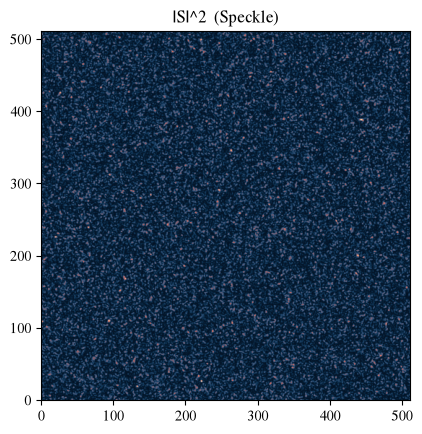

In [19]:
# Coordinate grid, 0 centred 
Y, X = np.indices((dimension, dimension))
X = X - dimension//2
Y = Y - dimension//2

#gaussian envelope
sigma_env = 80 #standard deviation # updated from original  
gaussian_env = np.exp(-(X**2 + Y**2) / (2 * sigma_env**2))

# Random complex matrix
rand_complex = (
    np.random.uniform(-1, 1, (dimension, dimension)) + 1j * np.random.uniform(-1, 1, (dimension, dimension))
)

# field at barrier
field = rand_complex * gaussian_env


# speckle pattern - random
speckle_rand = np.fft.fftshift(np.fft.fft2(field)) # fast fourier transform, shift to centre
intensity_rand = np.abs(speckle_rand)**2

plt.imshow(intensity_rand, origin='lower',cmap=cm.lipari )
plt.title("|S|^2  (Speckle)")
plt.show()

## Tracking Object

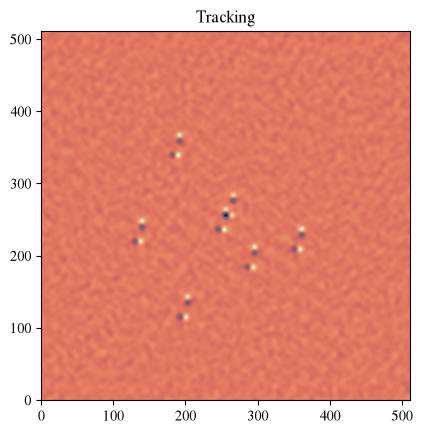

In [20]:

prev_image_clean = None
fft_speckle = np.fft.fft2(intensity_rand)
frame_list=[]

def track_object(frame):
    '''convolve object and speckle, track object using correlation I(t) ⋆ I(t-1) - I(t) ⋆ I(t)'''
    
    global prev_image_clean
    global fft_speckle
    t = 2 * np.pi * frame / frames_num
    Obj = make_object(t)

    # Convolution of speckle and object
    image = np.fft.ifft2(np.fft.fft2(Obj) * fft_speckle)
    image = np.real(image)

    # Remove background
    image_clean = image - np.mean(image)

    # for first frame
    if prev_image_clean is None:
        prev_image_clean = image_clean
        img.set_data(image_clean)
        img.set_clim(vmin=image_clean.min(), vmax=image_clean.max())
        return [img]

    # correlation - I(t) ⋆ I(t-1)
    correlation_shift = np.fft.ifft2(np.fft.fft2(image_clean) * np.conj(np.fft.fft2(prev_image_clean)))

    # correlation - I(t) ⋆ I(t)
    correlation_auto = np.fft.ifft2(np.fft.fft2(image_clean) * np.conj(np.fft.fft2(image_clean)))

    result = np.real(correlation_shift - correlation_auto)
    result = np.fft.fftshift(result)
    result=np.real(result)
    
    result -= np.mean(result)

    img.set_data(result)
    img.set_clim(vmin=result.min(), vmax=result.max())
    
    prev_image_clean = image_clean
    frame_list.append(result)

    return [img]

fig, ax = plt.subplots()
img = ax.imshow(np.zeros_like(intensity_rand), cmap=cm.lipari, animated=True,origin='lower',)

ax.set_title("Tracking")

#create animation
animation_tracking = FuncAnimation(fig, track_object, frames=frames_num, interval=80)

HTML(animation_tracking.to_jshtml())


# Background Shift Tracking

## Background shifts

In [21]:
from scipy.ndimage import gaussian_filter


reference_background = bg_frame[0]
reference_background = np.asarray(reference_background,dtype=float)

comparison_frame = np.asarray(frame_list[2],dtype=float)


#Calculate the cross-correlation 

reference_norm = np.sqrt(np.sum(reference_background**2))
comparison_frame_norm = np.sqrt(np.sum(comparison_frame**2))

correlation = np.fft.ifft2(np.fft.fft2(comparison_frame) * np.conj(np.fft.fft2(reference_background)))
correlation = np.real(correlation)
correlation = np.fft.fftshift(correlation)

# Normalise
correlation /= (reference_norm *comparison_frame_norm)


#Find the two strongest peaks

smooth = gaussian_filter(correlation,sigma=2)
flat = smooth.ravel()

candidates = np.argsort(flat)[::-1] # Look from highest correlation to lowest
peaks = []
min_separation = 20

for index in candidates:
    y, x = np.unravel_index(index,correlation.shape)

    too_close = False
    for py, px in peaks:
        distance = np.sqrt((y - py)**2 +(x - px)**2)
        if distance < min_separation:
            too_close = True
            break
    if not too_close:
        peaks.append((y, x))
    if len(peaks) == 2:
        break

# Convert peak positions into shifts

centre_y = correlation.shape[0] // 2
centre_x = correlation.shape[1] // 2

for i, (y, x) in enumerate(peaks):
    dx = x - centre_x
    dy = y - centre_y
    peak_value = correlation[y, x]
    print(
        f"Background {i+1}: "
        f"dx = {dx}, "
        f"dy = {dy}, "
        f"correlation peak = {peak_value}")







Background 1: dx = -6, dy = -20, correlation peak = 0.20973890247725174
Background 2: dx = 10, dy = -6, correlation peak = 0.19301491719444258


## Shifts For All Frames

In [22]:
y_shifts = []
x_shifts = []
for n in range(len(frame_list)-1):
    reference_background = bg_frame[0]
    reference_background = np.asarray(reference_background,dtype=float)

    comparison_frame = np.asarray(frame_list[n],dtype=float)


    #Calculate the cross-correlation 

    reference_norm = np.sqrt(np.sum(reference_background**2))
    comparison_frame_norm = np.sqrt(np.sum(comparison_frame**2))

    correlation = np.fft.ifft2(np.fft.fft2(comparison_frame) * np.conj(np.fft.fft2(reference_background)))
    correlation = np.real(correlation)
    correlation = np.fft.fftshift(correlation)

    # Normalise
    if comparison_frame_norm == 0:
        print(f"Frame {n+1} has zero norm")
    if reference_norm > 0 and comparison_frame_norm > 0:
        correlation /= (reference_norm * comparison_frame_norm)
    else:
        print(f"Skipping frame {n+1}")
        continue

    #Find the two strongest peaks

    smooth = gaussian_filter(correlation,sigma=2)
    flat = smooth.ravel()

    candidates = np.argsort(flat)[::-1] # Look from highest correlation to lowest
    peaks = []
    min_separation = 20

    for index in candidates:
        y, x = np.unravel_index(index,correlation.shape)

        too_close = False
        for py, px in peaks:
            distance = np.sqrt((y - py)**2 +(x - px)**2)
            if distance < min_separation:
                too_close = True
                break
        if not too_close:
            peaks.append((y, x))
        if len(peaks) == 2:
            break

    # Convert peak positions into shifts

    centre_y = correlation.shape[0] // 2
    centre_x = correlation.shape[1] // 2

    for i, (y, x) in enumerate(peaks):
        dx = x - centre_x
        dy = y - centre_y
        y_shifts.append(dy)
        x_shifts.append(dx)




Frame 1 has zero norm
Skipping frame 1
Frame 14 has zero norm
Skipping frame 14
Frame 39 has zero norm
Skipping frame 39


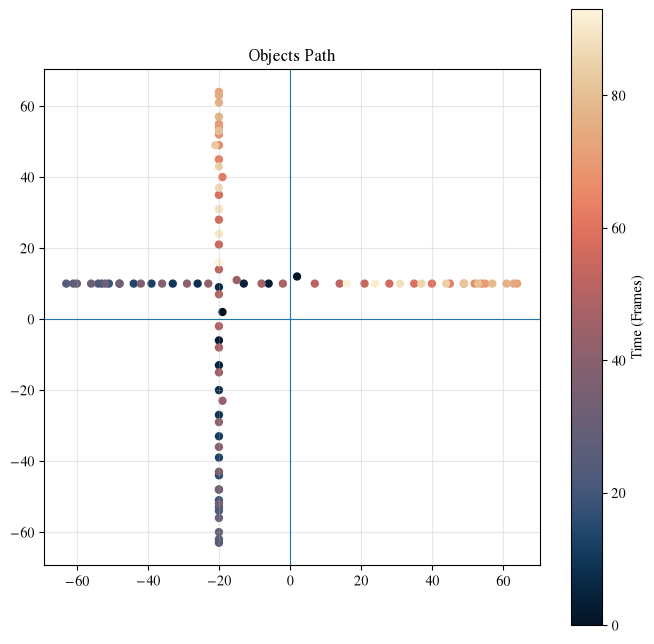

In [23]:
fig, ax = plt.subplots(figsize=(8, 8)) 
x_shifts = np.array(x_shifts)
y_shifts = np.array(y_shifts)

# Plot endpoints, coloured by frame number
scatter = ax.scatter(
    y_shifts,
    x_shifts,
    s=25,
    c=np.arange(len(x_shifts)),
    cmap=cm.lipari
)

plt.colorbar(scatter, ax=ax, label='Time (Frames)')
ax.axhline(0, linewidth=0.8) 
ax.axvline(0, linewidth=0.8) 

ax.set_title('Objects Path') 
ax.set_aspect('equal', adjustable='box') 
ax.grid(True, alpha=0.3) 

plt.show()

In [ ]:
'''from matplotlib.animation import PillowWriter
gif_writer = PillowWriter(fps=15)
combined_anim.save("Cross_tracking_two_object_linear_offset.gif", writer=gif_writer)'''

NameError: name 'combined_anim' is not defined

In [ ]:
%pip install imageio-ffmpeg
import matplotlib as mpl
import imageio_ffmpeg

mpl.rcParams["animation.ffmpeg_path"] = (
    imageio_ffmpeg.get_ffmpeg_exe()
)

print(mpl.rcParams["animation.ffmpeg_path"])

Note: you may need to restart the kernel to use updated packages.


In [28]:

from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

# --------------------------------------------------
# Prepare the estimated correlation shifts
# --------------------------------------------------
plot_x = -np.asarray(y_shifts, dtype=float)
plot_y = -np.asarray(x_shifts, dtype=float)

num_shift_points = min(len(plot_x), len(plot_y))
plot_x = plot_x[:num_shift_points]
plot_y = plot_y[:num_shift_points]

# --------------------------------------------------
# Reconstruct the fixed background using the same
# positions and blur as make_object()
# --------------------------------------------------
background = np.zeros((dimension, dimension))

for y, x in bg_positions:
    background[y, x] = 1

background = gaussian_filter(background, sigma=2)

# --------------------------------------------------
# Find the two moving objects in make_object(t)
# --------------------------------------------------
def find_moving_objects(t, previous_positions=None):
    """
    Get the two moving-object positions from make_object(t).

    The fixed background is subtracted first.
    If previous positions are supplied, assign each new
    position to the nearest previous position.
    """
    obj = make_object(t)
    moving = np.clip(obj - background, 0, None)

    # Identify bright candidate pixels
    threshold = moving.max() * 0.35
    candidates = np.argwhere(moving >= threshold)

    if len(candidates) < 2:
        # Fallback: take the two brightest pixels
        flat_indices = np.argpartition(moving.ravel(), -2)[-2:]
        candidates = np.array([
            np.unravel_index(p, moving.shape) for p in flat_indices
        ])

    # Keep one candidate near each previous object position
    if previous_positions is not None:
        selected = []
        remaining = list(candidates)

        for px, py in previous_positions:
            if not remaining:
                break

            distances = [
                (x - px)**2 + (y - py)**2
                for y, x in remaining
            ]
            index = int(np.argmin(distances))
            y, x = remaining.pop(index)
            selected.append((x, y))

        if len(selected) == 2:
            return selected

    # For the first frame, choose two candidates separated
    # by the greatest distance to avoid picking one blurred dot twice
    points = [(int(x), int(y)) for y, x in candidates]

    if len(points) > 2:
        p1 = points[0]
        p2 = max(
            points[1:],
            key=lambda p: (p[0] - p1[0])**2 + (p[1] - p1[1])**2
        )
        return [p1, p2]

    return points[:2]


# Precalculate the positions for every frame.
# This makes the animation smoother and preserves object identity.
object_positions = []
previous_positions = None

for frame in range(frames_num):
    t = 2 * np.pi * frame / frames_num

    positions = find_moving_objects(
        t,
        previous_positions=previous_positions
    )

    object_positions.append(positions)
    previous_positions = positions


# --------------------------------------------------
# Create the three plots
# --------------------------------------------------
fig, (ax_image, ax_actual, ax_shifts) = plt.subplots(
    1, 3, figsize=(18, 6)
)

# Left: original image
im = ax_image.imshow(
    make_object(0),
    origin="lower",
    cmap=cm.lipari,
    interpolation="nearest"
)
ax_image.set_title("Animation, +20 y_1, -10 x_2")
ax_image.set_xlabel("x (pixels)")
ax_image.set_ylabel("y (pixels)")

# Centre: positions extracted from make_object()
dot1, = ax_actual.plot(
    [], [], "o", markersize=8, label="Object 1"
)
dot2, = ax_actual.plot(
    [], [], "o", markersize=8, label="Object 2"
)

path1, = ax_actual.plot([], [], "-", alpha=0.7)
path2, = ax_actual.plot([], [], "-", alpha=0.7)

ax_actual.set_xlim(0, dimension)
ax_actual.set_ylim(0, dimension)
ax_actual.set_aspect("equal", adjustable="box")
ax_actual.set_title("Actual Object  Trajectories")
ax_actual.set_xlabel("x (pixels)")
ax_actual.set_ylabel("y (pixels)")
ax_actual.legend()
ax_actual.grid(alpha=0.3)

# Right: correlation-derived shifts
shift_scatter = ax_shifts.scatter(
    [], [],
    s=25,
    c=[],
    cmap=cm.lipari,
    vmin=0,
    vmax=max(num_shift_points - 1, 1)
)

ax_shifts.axhline(0, color="gray", linewidth=0.8)
ax_shifts.axvline(0, color="gray", linewidth=0.8)
ax_shifts.set_xlim(-100, 100)
ax_shifts.set_ylim(-100, 100)
ax_shifts.set_aspect("equal", adjustable="box")
ax_shifts.set_title("Calculated Path")
ax_shifts.set_xlabel("−dy (pixels)")
ax_shifts.set_ylabel("−dx (pixels)")
ax_shifts.grid(alpha=0.3)

fig.colorbar(
    shift_scatter,
    ax=ax_shifts,
    fraction=0.046,
    pad=0.04,
    label="Shift point order"
)

fig.tight_layout()


# --------------------------------------------------
# Animation update
# --------------------------------------------------
def update_triple(frame):
    t = 2 * np.pi * frame / frames_num

    # Left plot: original image from make_object()
    im.set_data(make_object(t))

    # Centre plot: positions extracted from make_object()
    positions = object_positions[frame]

    if len(positions) >= 2:
        x1, y1 = positions[0]
        x2, y2 = positions[1]

        dot1.set_data([x1], [y1])
        dot2.set_data([x2], [y2])

    # Show each object's trajectory up to the current frame
    path1.set_data(
        [p[0][0] for p in object_positions[:frame + 1]],
        [p[0][1] for p in object_positions[:frame + 1]]
    )

    path2.set_data(
        [p[1][0] for p in object_positions[:frame + 1]],
        [p[1][1] for p in object_positions[:frame + 1]]
    )

    # Right plot: progressively reveal estimated shifts
    visible_count = min(
        int((frame + 1) * num_shift_points / frames_num),
        num_shift_points
    )

    if visible_count > 0:
        offsets = np.column_stack((
            plot_x[:visible_count],
            plot_y[:visible_count]
        ))

        shift_scatter.set_offsets(offsets)
        shift_scatter.set_array(
            np.arange(visible_count, dtype=float)
        )
    else:
        shift_scatter.set_offsets(np.empty((0, 2)))
        shift_scatter.set_array(np.array([], dtype=float))

    return (
        im, dot1, dot2, path1, path2, shift_scatter
    )


# --------------------------------------------------
# Run the animation
# --------------------------------------------------
triple_anim = FuncAnimation(
    fig,
    update_triple,
    frames=frames_num,
    interval=80,
    blit=False
)


# Save the animation as a video
from matplotlib.animation import FFMpegWriter

writer = FFMpegWriter(fps=12, bitrate=1800)
triple_anim.save("cross_tracking_two_linear_offset.mp4", writer=writer, dpi=150)

plt.close(fig)
display(HTML(triple_anim.to_jshtml()))
